# SC benchmark — Scene Categorisation

Everything the paper reports for the scene-categorisation benchmark:

| Output | File |
|---|---|
| `SC_bench.pdf` — accuracy, median RT and predictive NLL against discriminability, every model against the human noise ceiling | `outputs/sc/SC_bench.pdf` |
| Table `tab:sc_perlevel` — Acc / AUC / $\kappa$ / NLL per discriminability level | `outputs/sc/sc_perlevel_table.tex` |
| Table `tab:sc_global` — the same metrics pooled, with bootstrap CIs | `outputs/sc/sc_global_table.tex` |

Models: **NRM** (DINOv2 backbone), **RTify**, **cRNN**, **LNR**, **LBA**,
**DDM** (the racing diffusion model). Highlighting in both tables is computed
here.

`RDM_bench.pdf` and `SC_bench.pdf` are the two halves of the paper's combined
`RDM_SC` figure; the last cell stacks them once `pipelines/rdm.ipynb` has run.

With `REFRESH = True` (or `REFRESH_WEIGHTS = True`) every output is written
with the `_REFRESH` suffix instead, next to the reference ones.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import warnings
warnings.filterwarnings('ignore')

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

# Canonical result layout (shared with ranking.ipynb), tables and figures.
from scripts import figures, results_io, tables
from scripts.results_io import save_global_results

OUTDIR = results_io.benchmark_dir('sc')
OUTDIR.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [2]:
PROB_LIST = tables.SC_LEVELS            # 0.2 .. 1.0 naturalness
MODEL_ORDER = figures.SC_MODEL_ORDER    # NRM, RTify, cRNN, LNR, LBA, DDM

DATA_CSV = ROOT / 'datasets' / 'sc' / 'experiment_1.csv'
# experiment_1.csv stores img as '<category>_<level>/<file>.jpg', already
# relative to the stimuli root.
IMG_DIR = ROOT / 'datasets' / 'sc' / 'stimuli'
SC_EMBEDDINGS = ROOT / 'embeddings' / 'sc' / 'sc_embeddings.pt'
NRM_WEIGHT = ROOT / 'nrm' / 'weights' / 'NRM_sc.pt'
COMP_WEIGHTS = ROOT / 'competitors' / 'weights' / 'sc'
PROJECTION_DIM = 18
SEEDS = [0, 1, 2, 3]
BATCH_SIZE = 128

# RT samples per trial: 50 for NRM, 100 for the classical comparators.
N_RT_SAMPLES_NRM = 50
N_RT_SAMPLES_COMP = 100
SEED = 42

# REFRESH = True recomputes every prediction from the models instead of loading
# caches.  REFRESH_WEIGHTS = True evaluates the retrained weights (*_REFRESH.pt[h])
# and implies REFRESH.  Either flag adds a _REFRESH suffix to every output file,
# leaving the reference outputs untouched.
REFRESH = False
REFRESH_WEIGHTS = False

REFRESH = REFRESH or REFRESH_WEIGHTS
TAG = results_io.refresh_tag(REFRESH)

RTIFY_CNN = COMP_WEIGHTS / 'rtify_cnn.pth'
RTIFY_ACCS = [COMP_WEIGHTS / f'rtify_accumulator_seed{s}.pth' for s in SEEDS]
CRNN_HGRU = COMP_WEIGHTS / 'crnn_hgru.pt'
CRNN_MAPPERS = [COMP_WEIGHTS / f'crnn_mapper_seed{s}.pt' for s in SEEDS]
if REFRESH_WEIGHTS:
    # A model without its retrained weights is skipped; with none at all the
    # run stops here.
    NRM_WEIGHT, RTIFY_CNN, *RTIFY_ACCS = (
        results_io.refresh_path(p, True) for p in [NRM_WEIGHT, RTIFY_CNN, *RTIFY_ACCS])
    CRNN_HGRU, *CRNN_MAPPERS = (
        results_io.refresh_path(p, True) for p in [CRNN_HGRU, *CRNN_MAPPERS])
    results_io.refresh_weights_available({
        'NRM': [NRM_WEIGHT], 'RTify': [RTIFY_CNN, *RTIFY_ACCS],
        'cRNN': [CRNN_HGRU, *CRNN_MAPPERS]})

NRM_CACHE = OUTDIR / f'nrm_predictions{TAG}.npz'
RTIFY_CACHE = OUTDIR / f'rtify_predictions{TAG}.npz'
CRNN_CACHE = OUTDIR / f'crnn_predictions{TAG}.npz'
COMP_CACHE = OUTDIR / f'classical_predictions{TAG}.npz'


def _save_cache(path, data):
    np.savez(path, **{k: v for k, v in data.items()
                      if k in ('pred_choices', 'pred_rts', 'prob_values')},
             rt_samples_by_prob=np.array(data.get('rt_samples_by_prob', {}), dtype=object),
             pred_probs_by_prob=np.array(data.get('pred_probs_by_prob', {}), dtype=object))


def _cache_usable(path):
    # One gate for all four models.
    if REFRESH:
        print(f'REFRESH=True — recomputing {path.name}')
        return False
    return path.exists()


def _load_cache(path):
    # savez stores the per-level dicts as 0-d object arrays; unwrap them or
    # every later lookup indexes the wrapper instead of the dict.
    c = np.load(path, allow_pickle=True)
    return {k: (c[k].item() if c[k].shape == () else c[k]) for k in c.files}

## 1. Load Data

`embeddings/sc/sc_embeddings.pt` holds the three splits already projected
to 18 dimensions.

In [3]:
from datasets.sc.loader import SCDataset, sc_collate_fn
from torch.utils.data import DataLoader

dataset = SCDataset(
    csv_path=str(DATA_CSV),
    image_dir=str(IMG_DIR),
    load_images=False,
)

# Split by image, seed 42 — identical to training and to the competitors.
train_ds, val_ds, test_ds = dataset.train_val_test_split(
    val_size=0.10, test_size=0.20, seed=42,
)

if not SC_EMBEDDINGS.exists():
    raise FileNotFoundError(
        f'{SC_EMBEDDINGS.relative_to(ROOT)} not found.\n'
        'Generate it with: python embeddings/sc/compute_embeddings.py'
    )
emb_data = torch.load(SC_EMBEDDINGS, weights_only=False)
for split, subset in (('train', train_ds), ('val', val_ds), ('test', test_ds)):
    emb = emb_data[split]
    assert len(emb) == len(subset), (
        f'{split}: {len(emb)} embeddings vs {len(subset)} trials — '
        'regenerate with embeddings/sc/compute_embeddings.py'
    )
    subset.embeddings = emb

test_df = test_ds.df.copy()
print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')
print(f'Projected embedding dim: {test_ds.embeddings.shape[1]} '
      f'(expected {PROJECTION_DIM})')

# BATCH_SIZE (128) is part of the protocol, not a performance knob: torchsde
# draws one Brownian entropy per sdeint call, so the number of batches changes
# the SDE paths.
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    collate_fn=sc_collate_fn, pin_memory=torch.cuda.is_available(),
)

bad_trial removal: 383 rows removed, 7297 remaining.
Dataset ready: 7297 trials, 960 unique images, 8 subjects.
  train: 5105 trials (672 images)
  val  : 727 trials (96 images)
  test : 1465 trials (192 images)
Train: 5105 | Val: 727 | Test: 1465
Projected embedding dim: 18 (expected 18)


## 2. NRM Predictions

In [4]:
from nrm.config import build_model
from scripts.eval_sc import SCEvaluator

nrm_data = None

if not NRM_WEIGHT.exists():
    print(f'Skipping NRM — missing weights: {NRM_WEIGHT.name}')
    print('Produce them with: python scripts/train_nrm_sc.py')
else:
    # build_model('sc') applies the SC configuration from nrm/config.py
    # (2 choices, cond_dim 32 over the 18-d projection, t_max 3 s), so the
    # architecture cannot drift from the one the weights were trained with.
    nrm = build_model('sc', device=device)
    ckpt = torch.load(NRM_WEIGHT, map_location=device)
    nrm.load_state_dict(ckpt.get('model_state_dict', ckpt))
    nrm.eval()
    print(f'NRM loaded from {NRM_WEIGHT.name}')

    if _cache_usable(NRM_CACHE):
        print(f'Loading cached NRM predictions from {NRM_CACHE.name}')
        nrm_data = _load_cache(NRM_CACHE)
    else:
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        evaluator = SCEvaluator(model=nrm, device=device, n_choices=2,
                                prob_list=PROB_LIST)
        nrm_data = evaluator.collect_predictions(test_loader,
                                                 n_rt_samples=N_RT_SAMPLES_NRM)
        _save_cache(NRM_CACHE, nrm_data)
        print(f'Cached NRM predictions to {NRM_CACHE.name}')

NRM loaded from NRM_sc.pt
Loading cached NRM predictions from nrm_predictions.npz


## 3. RTify Predictions

The shipped weights are the frozen CNN backbone pre-trained on SUN_filtered
plus four accumulator heads, one per seed. RTify is deterministic at inference,
so its RT distribution comes from the spread across those seeds; the reported
choice and RT are the median over them.

In [5]:
rtify_data = None

if _cache_usable(RTIFY_CACHE):
    print(f'Loading cached RTify predictions from {RTIFY_CACHE.name}')
    rtify_data = _load_cache(RTIFY_CACHE)
else:
    from competitors.rtify.train_sc import (
        Accumulator, CNNEncoder, RTifyModel, SCImageDataset,
        build_eval_data as rtify_build_eval_data,
    )

    cnn_path, acc_paths = RTIFY_CNN, RTIFY_ACCS
    missing = [p.name for p in [cnn_path] + acc_paths if not p.exists()]
    if missing:
        print('Skipping RTify — missing weights:', ', '.join(missing))
        print('Produce them with: python competitors/rtify/train_sc.py')
    else:
        encoder = CNNEncoder(feat_dim=128).to(device)
        encoder.load_state_dict(torch.load(cnn_path, map_location=device))
        encoder.eval()

        models = []
        for p in acc_paths:
            acc = Accumulator(feat_dim=128, hidden_dim=128, n_classes=2,
                              time_steps=40, sigma=2.0).to(device)
            acc.load_state_dict(torch.load(p, map_location=device))
            acc.eval()
            models.append(RTifyModel(encoder=encoder, accumulator=acc).to(device).eval())

        # RT normalisation comes from the val split, as in training.
        val_rts = val_ds.df['rt'].dropna().values.astype(np.float32)
        rt_min = float(val_rts.min())
        rt_range = max(float(val_rts.max() - val_rts.min()), 1e-6)
        print(f'RT normalisation (val split): min={rt_min:.4f}s range={rt_range:.4f}s')

        rtify_data = rtify_build_eval_data(
            models=models, test_img_ds=SCImageDataset(test_ds),
            batch_size=BATCH_SIZE, device=device,
            rt_min=rt_min, rt_range=rt_range,
        )
        _save_cache(RTIFY_CACHE, rtify_data)
        print(f'Cached RTify predictions to {RTIFY_CACHE.name}')

Loading cached RTify predictions from rtify_predictions.npz


## 4. cRNN Predictions

The cRNN emits a scalar proportional to decision time rather than an RT in
seconds, so a linear mapper fitted on the validation split converts it; four
seeds give the distribution.

In [6]:
crnn_data = None

if _cache_usable(CRNN_CACHE):
    print(f'Loading cached cRNN predictions from {CRNN_CACHE.name}')
    crnn_data = _load_cache(CRNN_CACHE)
else:
    from competitors.crnn.train_sc import (
        RTMapper, SCImageDataset as CRNNImageDataset, hGRU,
        build_eval_data as crnn_build_eval_data,
    )

    hgru_path, mapper_paths = CRNN_HGRU, CRNN_MAPPERS
    missing = [p.name for p in [hgru_path] + mapper_paths if not p.exists()]
    if missing:
        print('Skipping cRNN — missing weights:', ', '.join(missing))
        print('Produce them with: python competitors/crnn/train_sc.py')
    else:
        crnn = hGRU(
            timesteps=40, filt_size=15, num_iter=15, exp_name='sc_crnn',
            jacobian_penalty=True, grad_method='rbp', activ='softplus',
            xavier_gain=1.0, num_channels=25, n_in=1, n_classes=2,
        ).to(device)
        crnn.load_state_dict(torch.load(hgru_path, map_location=device))
        crnn.eval()

        mappers = []
        for p in mapper_paths:
            m = RTMapper().to(device)
            m.load_state_dict(torch.load(p, map_location=device))
            m.eval()
            mappers.append(m)

        crnn_data = crnn_build_eval_data(
            model=crnn, mappers=mappers,
            sc_image_ds=CRNNImageDataset(test_ds),
            batch_size=BATCH_SIZE, device=device,
        )
        _save_cache(CRNN_CACHE, crnn_data)
        print(f'Cached cRNN predictions to {CRNN_CACHE.name}')

Loading cached cRNN predictions from crnn_predictions.npz


## 5. Classical Competitors (LNR / LBA / DDM)

In [7]:
from collections import defaultdict

from competitors import (
    prepare_data, fit_lnr, fit_lba, fit_ddm,
    simulate_lnr_with_samples, simulate_lba, simulate_ddm,
)


def sc_to_competitor_df(ds):
    # Rename SC columns to the schema the classical fitters expect.
    # 'choice' is the ground-truth category (0=natural, 1=manmade) derived
    # from the filename; 'human_choice' is what the observer pressed.
    out = ds.df[['image_index', 'choice', 'human_choice', 'rt', 'correct']].copy()
    return out.rename(columns={'choice': 'stim', 'human_choice': 'response',
                               'rt': 'resp_rt'})


def img_rt_pool_to_level(rt_by_img):
    # The simulators return their RT samples keyed by `image_index`; the NLL is
    # evaluated per discriminability level, so collapse images onto the level
    # they belong to. One entry per *trial*, so an image seen by several
    # observers weighs as often as it was seen.
    #
    # Keys are snapped onto PROB_LIST: the levels come off the CSV as floats
    # and `_rt_pool_for` looks them up by equality, so a 1e-17 difference would
    # silently miss and fall back to the per-trial RTs.
    by_level = defaultdict(list)
    for img, level in zip(test_df['image_index'].astype(int),
                          test_df['prob'].astype(float)):
        samples = rt_by_img.get(int(img))
        if samples is None:
            continue
        key = min(PROB_LIST, key=lambda p: abs(p - float(level)))
        by_level[key].extend(samples[:N_RT_SAMPLES_COMP])
    return {k: np.asarray(v, dtype=float) for k, v in by_level.items()}


if _cache_usable(COMP_CACHE):
    print(f'Loading cached classical predictions from {COMP_CACHE.name}')
    _c = np.load(COMP_CACHE, allow_pickle=True)
    lnr_pred_choices, lnr_pred_rts = _c['lnr_pred_choices'], _c['lnr_pred_rts']
    lba_pred_choices, lba_pred_rts = _c['lba_pred_choices'], _c['lba_pred_rts']
    ddm_pred_choices, ddm_pred_rts = _c['ddm_pred_choices'], _c['ddm_pred_rts']
    # savez stores a dict as a 0-d object array; .item() unwraps it.
    lnr_rt_by_level = _c['lnr_rt_by_level'].item()
    lba_rt_by_level = _c['lba_rt_by_level'].item()
    ddm_rt_by_level = _c['ddm_rt_by_level'].item()
else:
    test_comp = sc_to_competitor_df(test_ds)
    # prepare_data filters extreme RTs; it takes rt bounds, not n_choices.
    train_fit = prepare_data(sc_to_competitor_df(train_ds))
    print(f'Competitor training data: {len(train_fit)} trials')

    # All three simulators share one signature —
    #   (params, test_data, n_choices, n_rt_samples, rng)
    #     -> (choices, rts, rt_samples_by_image)
    # — and return a tuple aligned with test_df. (`simulate_lnr` is a different
    # entry point: it takes a trial count and returns a DataFrame of synthetic
    # trials, with no alignment to test_df.)
    print('Fitting LNR...')
    lnr_result = fit_lnr(train_fit, n_choices=2)
    lnr_pred_choices, lnr_pred_rts, lnr_rt_by_img = simulate_lnr_with_samples(
        lnr_result.x, test_data=test_comp, n_choices=2,
        n_rt_samples=N_RT_SAMPLES_COMP, rng=np.random.default_rng(SEED))

    print('Fitting LBA...')
    lba_result = fit_lba(train_fit, n_choices=2)
    lba_pred_choices, lba_pred_rts, lba_rt_by_img = simulate_lba(
        lba_result.x, test_data=test_comp, n_choices=2,
        n_rt_samples=N_RT_SAMPLES_COMP, rng=np.random.default_rng(SEED))

    # "DDM" in the paper's tables is the racing diffusion model.
    print('Fitting DDM (racing diffusion)...')
    ddm_result = fit_ddm(train_fit, n_choices=2)
    ddm_pred_choices, ddm_pred_rts, ddm_rt_by_img = simulate_ddm(
        ddm_result.x, test_data=test_comp, n_choices=2,
        n_rt_samples=N_RT_SAMPLES_COMP, rng=np.random.default_rng(SEED))

    lnr_rt_by_level = img_rt_pool_to_level(lnr_rt_by_img)
    lba_rt_by_level = img_rt_pool_to_level(lba_rt_by_img)
    ddm_rt_by_level = img_rt_pool_to_level(ddm_rt_by_img)

    np.savez(COMP_CACHE,
             lnr_pred_choices=lnr_pred_choices, lnr_pred_rts=lnr_pred_rts,
             lba_pred_choices=lba_pred_choices, lba_pred_rts=lba_pred_rts,
             ddm_pred_choices=ddm_pred_choices, ddm_pred_rts=ddm_pred_rts,
             lnr_rt_by_level=lnr_rt_by_level, lba_rt_by_level=lba_rt_by_level,
             ddm_rt_by_level=ddm_rt_by_level)
    print(f'Cached classical predictions to {COMP_CACHE.name}')

print('RT pool sizes (LBA):', {k: len(v) for k, v in sorted(lba_rt_by_level.items())})

Loading cached classical predictions from classical_predictions.npz
RT pool sizes (LBA): {0.2: 21400, 0.4: 28000, 0.6: 34300, 0.8: 37600, 1.0: 25200}


## 6. Per-Trial Index Arrays

In [8]:
prob_values = test_df['prob'].values.astype(float)
true_labels = test_df['choice'].values.astype(int)
human_choices = test_df['human_choice'].values.astype(int)
human_rts = test_df['rt'].values.astype(float)
subj_ids = test_df['subj_idx'].values.astype(str)

# One entry per model: per-trial choices and RTs, plus the pool the KDE is
# fitted to at each level. Every model draws more than one RT per trial, so
# every row carries a pool — using the per-trial point prediction instead for
# the comparators would make the NLL column measure a different thing for them
# than for NRM.
PREDICTIONS = {
    'LNR': dict(choices=lnr_pred_choices, rts=lnr_pred_rts,
                rt_pool=lnr_rt_by_level),
    'LBA': dict(choices=lba_pred_choices, rts=lba_pred_rts,
                rt_pool=lba_rt_by_level),
    'DDM': dict(choices=ddm_pred_choices, rts=ddm_pred_rts,
                rt_pool=ddm_rt_by_level),
}
for name, payload in (('NRM', nrm_data), ('RTify', rtify_data), ('cRNN', crnn_data)):
    if payload is not None:
        PREDICTIONS[name] = dict(
            choices=payload['pred_choices'], rts=payload['pred_rts'],
            rt_pool=payload.get('rt_samples_by_prob'),
            probs_by_level=payload.get('pred_probs_by_prob'),
        )

for name, spec in PREDICTIONS.items():
    assert len(spec['choices']) == len(test_df), (
        f'{name}: {len(spec["choices"])} predictions for {len(test_df)} trials')

print(f'Test set: {len(test_df)} trials, {len(PROB_LIST)} discriminability '
      f'levels, {len(np.unique(subj_ids))} subjects')
print('Models with predictions:', ', '.join(k for k in MODEL_ORDER if k in PREDICTIONS))


def roster_caveat():
    # Printed above each table: bold/underline rank only what was evaluated.
    absent = [k for k in MODEL_ORDER if k not in PREDICTIONS]
    if not absent:
        return ''
    return ('[INCOMPLETE ROSTER] bold/underline rank only the models present. '
            f'Missing: {", ".join(absent)}. '
            'Produce them before using this table.\n')

Test set: 1465 trials, 5 discriminability levels, 8 subjects
Models with predictions: NRM, RTify, cRNN, LNR, LBA, DDM


## 7. Metrics

Per discriminability level, for every model: accuracy against ground truth,
AUC, Cohen's $\kappa$, and the negative log-likelihood of the human RTs under a
KDE fitted to the model's RT samples. The human noise ceiling uses the same
definitions, with leave-one-trial-out KDE for its NLL.

The *Avg* column and the global table share one computation, which is **not**
uniform across columns:

| column | basis |
|---|---|
| Acc | **pooled over all test trials** (`acc`) |
| AUC, $\kappa$ | mean over the five levels (`mean_auc`, `mean_kappa`) |
| NLL | mean over the five levels of the per-level KDE likelihood |
| $r_{\rm RT}$ | Pearson between model and human **per-level median RT**, where the model's median is taken over its *pooled RT sample cloud* |
| Human (NC) Acc / AUC / $\kappa$ | pooled over all test trials (`compute_human_nc_global`) |
| Human (NC) $r_{\rm RT}$ | split-half reliability across trials |


In [9]:
from metrics.point_metrics import safe_auc, safe_kappa
from metrics.rt_likelihood import kde_nll, kde_nll_pertrial, loto_nll
from scripts.eval_sc import NLL_RT_RANGE, compute_human_nc_global

RT_MS = 1000.0


def _level_mask(level):
    return np.isclose(prob_values, level)


def _probs_for(spec, level, mask):
    # AUC needs a score, not a label. NRM and the two seed-ensembled models
    # emit a graded score; the classical models emit a hard choice, so their
    # AUC collapses onto balanced accuracy.
    by_level = spec.get('probs_by_level')
    if by_level:
        for key in (level, round(float(level), 1), f'{level:.1f}'):
            p = np.asarray(by_level.get(key, []), dtype=float)
            if len(p) == int(mask.sum()):
                return p
    return np.asarray(spec['choices'], dtype=float)[mask]


def _rt_pool_for(spec, level, mask):
    pool = spec.get('rt_pool')
    if pool:
        for key in (level, round(float(level), 1), f'{level:.1f}'):
            if key in pool:
                return np.asarray(pool[key], dtype=float)
    return np.asarray(spec['rts'], dtype=float)[mask]


def per_level_metrics(spec):
    # {level: {Acc, AUC, kappa, NLL, RT (ms)}} plus the per-trial NLL terms.
    out, nll_terms = {}, []
    for level in PROB_LIST:
        mask = _level_mask(level)
        if mask.sum() == 0:
            continue
        t_lb = true_labels[mask]
        p_ch = np.asarray(spec['choices'])[mask]
        p_rt = np.asarray(spec['rts'], dtype=float)[mask]
        h_rt = human_rts[mask]
        pool = _rt_pool_for(spec, level, mask)
        pool = pool[np.isfinite(pool)]

        out[level] = dict(
            Acc=float(np.mean(p_ch == t_lb)),
            AUC=safe_auc(t_lb, _probs_for(spec, level, mask)),
            kappa=safe_kappa(t_lb, p_ch),
            NLL=kde_nll(h_rt, pool, rt_range=NLL_RT_RANGE),
            # Median of the *pooled sample cloud*, not of the per-trial point
            # prediction (`np.median(rt_samples_by_prob[prob])`); this value
            # feeds both the chronometric panel and r_RT. RDM uses the
            # per-trial median instead — see pipelines/rdm.ipynb.
            RT=(float(np.median(pool)) * RT_MS if len(pool)
                else float(np.median(p_rt)) * RT_MS),
        )
        nll_terms.extend(kde_nll_pertrial(h_rt, pool, rt_range=NLL_RT_RANGE).tolist())
    return out, np.asarray(nll_terms, dtype=float)


def human_per_level_metrics():
    out = {}
    for level in PROB_LIST:
        mask = _level_mask(level)
        if mask.sum() == 0:
            continue
        t_lb, h_ch, h_rt = true_labels[mask], human_choices[mask], human_rts[mask]
        out[level] = dict(
            Acc=float(np.mean(h_ch == t_lb)),
            AUC=safe_auc(t_lb, h_ch.astype(float)),
            kappa=safe_kappa(t_lb, h_ch),
            NLL=loto_nll(h_rt, rt_range=NLL_RT_RANGE),
            RT=float(np.median(h_rt)) * RT_MS,
        )
    return out


def _mean(vals):
    v = [x for x in vals if np.isfinite(x)]
    return float(np.mean(v)) if v else float('nan')


per_level, nll_terms = {}, {}
for name in MODEL_ORDER:
    if name not in PREDICTIONS:
        continue
    print(f'Computing {name} metrics ...')
    per_level[name], nll_terms[name] = per_level_metrics(PREDICTIONS[name])

human_per_level = human_per_level_metrics()
human_rt_curve = [human_per_level[p]['RT'] for p in PROB_LIST if p in human_per_level]

globals_ = {}
for name, pl in per_level.items():
    spec = PREDICTIONS[name]
    levels_present = [p for p in PROB_LIST if p in pl]
    model_rt_curve = [pl[p]['RT'] for p in levels_present]
    r_rt = (float(pearsonr(model_rt_curve, human_rt_curve)[0])
            if len(levels_present) >= 3 and np.std(model_rt_curve) > 0 else float('nan'))
    terms = nll_terms[name][np.isfinite(nll_terms[name])]
    # Per-trial score array for the bootstrap below, aligned with test_df.
    probs = np.asarray(spec['choices'], dtype=float).copy()
    for level in PROB_LIST:
        mask = _level_mask(level)
        p = _probs_for(spec, level, mask)
        if len(p) == int(mask.sum()):
            probs[mask] = p
    # Acc is pooled over trials; AUC and kappa are means over levels, as
    # `SCEvaluator.compute_metrics` returns them (`acc`, `mean_auc`,
    # `mean_kappa`).
    pooled_acc = float((np.asarray(spec['choices']).astype(int) == true_labels).mean())
    globals_[name] = {
        'Acc': pooled_acc,
        'AUC': _mean([pl[p]['AUC'] for p in levels_present]),
        'kappa': _mean([pl[p]['kappa'] for p in levels_present]),
        'r_RT': r_rt,
        'NLL': _mean([pl[p]['NLL'] for p in levels_present]),
        'NLL_sem': (float(np.std(terms, ddof=1) / np.sqrt(len(terms)))
                    if len(terms) > 1 else float('nan')),
        '_probs': probs,
    }

# Human noise ceiling. Acc / AUC / kappa come straight from
# `compute_human_nc_global`, which pools over trials. r_RT has no per-level
# analogue (split-half reliability across trials), and the NLL is the mean of
# the per-level leave-one-trial-out values.
nc_pooled = compute_human_nc_global(human_choices, true_labels, human_rts,
                                    prob_values, PROB_LIST)
levels_present = [p for p in PROB_LIST if p in human_per_level]
human_global = {
    'Acc': nc_pooled['acc'],
    'AUC': nc_pooled['auc'],
    'kappa': nc_pooled['kappa'],
    'r_RT': nc_pooled['r_rt'],
    'NLL': _mean([human_per_level[p]['NLL'] for p in levels_present]),
}
print('Human (NC): pooled over trials (reported) vs mean over levels')
for k, pooled_key in (('Acc', 'acc'), ('AUC', 'auc'), ('kappa', 'kappa')):
    mean_over_levels = _mean([human_per_level[p][k] for p in levels_present])
    print(f'  {k:6s} {nc_pooled[pooled_key]:.3f}  '
          f'(mean over levels {mean_over_levels:.3f})')

print('\nGlobal values')
print(f"  {'model':8s} {'Acc':>7s} {'AUC':>7s} {'kappa':>7s} {'r_RT':>7s} {'NLL':>8s}")
for name, g in [('Human', human_global)] + [(n, globals_[n]) for n in MODEL_ORDER
                                            if n in globals_]:
    print(f"  {name:8s} {g['Acc']:7.3f} {g['AUC']:7.3f} {g['kappa']:7.3f} "
          f"{g['r_RT']:7.3f} {g['NLL']:8.3f}")

Computing NRM metrics ...
Computing RTify metrics ...
Computing cRNN metrics ...
Computing LNR metrics ...
Computing LBA metrics ...
Computing DDM metrics ...
Human (NC): pooled over trials (reported) vs mean over levels
  Acc    0.840  (mean over levels 0.835)
  AUC    0.840  (mean over levels 0.835)
  kappa  0.679  (mean over levels 0.667)

Global values
  model        Acc     AUC   kappa    r_RT      NLL
  Human      0.840   0.840   0.679   0.263   -1.413
  NRM        0.834   0.916   0.666   0.791   -0.301
  RTify      0.786   0.873   0.562   0.791   -0.042
  cRNN       0.611   0.627   0.240   0.713   -1.063
  LNR        0.491   0.493  -0.015   0.493   -1.394
  LBA        0.513   0.518   0.033   0.170   -1.353
  DDM        0.509   0.507   0.013   0.357   -1.380


## 8. Bootstrap confidence intervals

95 % intervals from B = 1000 resamples of the test **trials**, re-aggregated
per level exactly as the point estimates are.

In [10]:
cis = {}
for name in MODEL_ORDER:
    if name not in globals_:
        continue
    spec = PREDICTIONS[name]
    print(f'  bootstrapping {name} (B=1000) ...')
    cis[name] = tables.bootstrap_choice_rt_cis(
        level_values=prob_values,
        true_labels=true_labels,
        pred_choices=np.asarray(spec['choices']),
        pred_probs=globals_[name]['_probs'],
        human_rts=human_rts,
        pred_rts=np.asarray(spec['rts'], dtype=float),
        levels=PROB_LIST,
        auc_fn=safe_auc,
        kappa_fn=safe_kappa,
        B=1000, seed=42,
    )
    cis[name]['NLL_sem'] = globals_[name]['NLL_sem']
print('Done.')

  bootstrapping NRM (B=1000) ...
  bootstrapping RTify (B=1000) ...
  bootstrapping cRNN (B=1000) ...
  bootstrapping LNR (B=1000) ...
  bootstrapping LBA (B=1000) ...
  bootstrapping DDM (B=1000) ...
Done.


## 9. Table `tab:sc_perlevel`

In [11]:
perlevel_tex = tables.sc_per_level_table(
    per_level, human_per_level, levels=PROB_LIST,
    avg=globals_, human_avg=human_global,
)
(OUTDIR / f'sc_perlevel_table{TAG}.tex').write_text(perlevel_tex)
print(roster_caveat() + perlevel_tex)
print(f"\nSaved -> {(OUTDIR / f'sc_perlevel_table{TAG}.tex').relative_to(ROOT)}")

\begin{table}[t]
  \centering
  \caption{SC task: each block shows one metric across discriminability levels $\{$0.2, 0.4, 0.6, 0.8, 1.0$\}$. NRM has DINOv2 as visual backbone. \textit{Avg}: mean over the levels, for every row (identical to the global table). Superscript grey values give $|\Delta|$ from Human~(NC). \textbf{Bold} = best model per column, \underline{underline} = second best (smallest $|\Delta|$, lowest value for NLL).}
  \label{tab:sc_perlevel}
  \scriptsize
  \setlength{\tabcolsep}{3pt}
  \resizebox{\linewidth}{!}{%
  \begin{tabular}{@{} ll ccccc c @{}}
    \toprule
    & & \multicolumn{5}{c}{\textbf{Discriminability Levels}} & \\
    \cmidrule(lr){3-7}
    \textbf{Model} & \textbf{Metric} & 0.2 & 0.4 & 0.6 & 0.8 & 1.0 & \textit{Avg} \\
    \midrule
    \multirow{4}{*}{\begin{tabular}[c]{@{}l@{}}Human\\(NC)\end{tabular}} & Acc & 0.738 & 0.818 & 0.825 & 0.880 & 0.913 & 0.840 \\
     & AUC & 0.744 & 0.816 & 0.825 & 0.881 & 0.909 & 0.840 \\
     & $\kappa$ & 0.477 & 0.634 

## 10. Table `tab:sc_global`

In [12]:
global_tex = tables.sc_global_table(globals_, human_global, cis)
(OUTDIR / f'sc_global_table{TAG}.tex').write_text(global_tex)
print(roster_caveat() + global_tex)
print(f"\nSaved -> {(OUTDIR / f'sc_global_table{TAG}.tex').relative_to(ROOT)}")

\begin{table}[t]
  \centering
  \caption{Scene Categorisation. Choice performance is measured by Acc, AUC, and Cohen's~$\kappa$ ($\kappa_{\mathrm{acc}}$); RT alignment by $r_{\rm RT}$ (correlation of per-discriminability median RT); and RT distribution fit by NLL. \textbf{Bold} = best; \underline{underline} = second best (relative to NC, or absolute for $r_{\rm RT}$ and NLL). Asymmetric 95\% CIs (bootstrap, $B{=}1000$) shown as superscripts/subscripts; NLL reports $\pm$ Std. Error of the Mean.}
  \label{tab:sc_global}
  \footnotesize
  \setlength{\tabcolsep}{5pt}
  \renewcommand{\arraystretch}{1.4}
  \resizebox{.85\linewidth}{!}{%
  \begin{tabular}{@{} l ccc cc @{}}
    \toprule
    & \multicolumn{3}{c}{\textbf{Choice}}
    & \multicolumn{2}{c}{\textbf{RT}} \\
    \cmidrule(lr){2-4} \cmidrule(lr){5-6}
    \textbf{Model}
      & Acc ($|\Delta|\!\downarrow$)
      & AUC ($|\Delta|\!\downarrow$)
      & $\kappa_{\mathrm{acc}}$ ($|\Delta|\!\downarrow$)
      & $r_{\rm RT}$ ($\uparrow$)
   

## 11. Figure — `SC_bench.pdf`

Three panels against discriminability: the psychometric function, the
chronometric function and the predictive NLL. The human band is $\pm 1$
standard deviation across subjects.

Saved -> outputs/sc/SC_bench.pdf


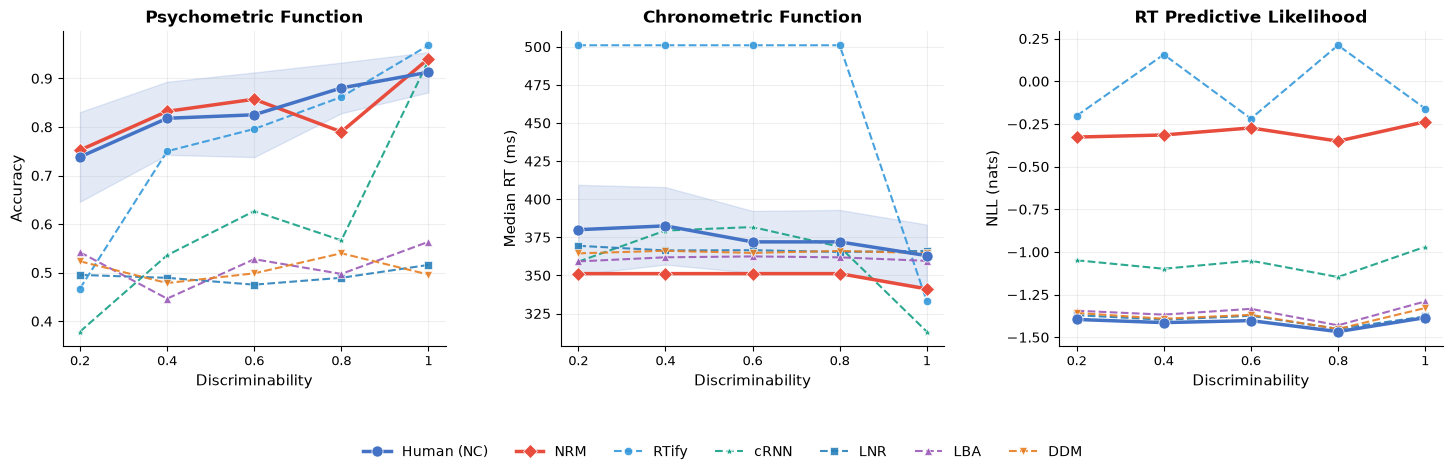

In [13]:
subjects = np.unique(subj_ids)
acc_by_sub = np.full((len(subjects), len(PROB_LIST)), np.nan)
rt_by_sub = np.full((len(subjects), len(PROB_LIST)), np.nan)
for si, s in enumerate(subjects):
    for li, level in enumerate(PROB_LIST):
        m = (subj_ids == s) & _level_mask(level)
        if m.sum() >= 1:
            acc_by_sub[si, li] = np.mean(human_choices[m] == true_labels[m])
            rt_by_sub[si, li] = np.median(human_rts[m]) * RT_MS

human_bands = {
    'Acc': np.nanstd(acc_by_sub, axis=0),
    'RT': np.nanstd(rt_by_sub, axis=0),
}

fig = figures.plot_sc_bench(
    per_level, human_per_level, PROB_LIST,
    save_path=OUTDIR / f'SC_bench{TAG}.pdf',
    human_bands=human_bands,
)
plt.show()

## 12. Save Results

In [14]:
# ranking.ipynb reads nll_mean / acc / auc / kappa / r_RT per model, so the
# keys it expects are written here alongside the human noise ceiling.
ranking_payload = {
    name: {'global': {'acc': g['Acc'], 'auc': g['AUC'], 'kappa': g['kappa'],
                      'r_RT': g['r_RT'], 'nll_mean': g['NLL']}}
    for name, g in globals_.items()
}
ranking_payload['Human (NC)'] = {'global': {
    'acc': human_global['Acc'], 'auc': human_global['AUC'],
    'kappa': human_global['kappa'], 'r_RT': human_global['r_RT'],
    'nll_mean': human_global['NLL'],
}}
path = save_global_results('sc', ranking_payload, refresh=REFRESH)
print(f'Results written to {path.relative_to(ROOT)}')

for name in (f'SC_bench{TAG}.pdf', f'sc_perlevel_table{TAG}.tex', f'sc_global_table{TAG}.tex'):
    p = OUTDIR / name
    print(f"{'OK  ' if p.exists() else 'MISS'} {p.relative_to(ROOT)}")

# RDM_SC.pdf is RDM_bench stacked over SC_bench.
figures.stack_bench_figures(
    results_io.benchmark_dir('rdm') / f'RDM_bench{TAG}.pdf',
    OUTDIR / f'SC_bench{TAG}.pdf',
    OUTDIR / f'RDM_SC{TAG}.pdf',
)

print('\nNext: run pipelines/ranking.ipynb to aggregate across benchmarks.')

Results written to outputs/sc/sc_global_results.json
OK   outputs/sc/SC_bench.pdf
OK   outputs/sc/sc_perlevel_table.tex
OK   outputs/sc/sc_global_table.tex


Saved -> outputs/sc/RDM_SC.pdf

Next: run pipelines/ranking.ipynb to aggregate across benchmarks.
